# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170122
NAME ="Adaa Goyal"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170122   Name: Adaa Goyal   Fingerprint: A8A6BD97   Tickets: 14

Ticket_ID                                                                             Ticket_Text
      T01                                         The laptop is showing an error. This is urgent.
      T02   Laptop has stopped syncing before the assignment deadline. Is there another solution?
      T03                              The Wi-Fi keeps disconnecting. I have tried several times!
      T04                          The printer keeps asking for login. Is there another solution?
      T05                                                             My roll no. is 1023-03-021.
      T06                 VPN is not working when connected to campus Wi-Fi. It worked yesterday.
      T07 I was locked out of the e-mail after resetting my password. I have tried several times!
      T08                                                   The Wi-Fi works, but the VPN doesn't.
      T09           Email keeps disc

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Assignment 7 - Question 1
# Roll Number: 1024170122

import pandas as pd

print("Q1: Preprocessing Pipeline")
print("Fingerprint:", FINGERPRINT)

results = []
processed_tickets = {}

# Apply process_ticket() to every ticket
for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    processed = process_ticket(text)

    processed_tickets[ticket_id] = processed

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(processed["sentences"]),
        "Tokens": len(processed["tokens"]),
        "Punctuation": len(processed["punct"]),
        "Stopwords": len(processed["stops"]),
        "Unique_Tokens": len(set(processed["tokens"])),
        "Final_Tokens": len(processed["final"])
    })

# Create DataFrame
result_df = pd.DataFrame(results)

# Calculate totals
total_row = {"Ticket_ID": "TOTAL"}

for col in result_df.columns[1:]:
    total_row[col] = result_df[col].sum()

# Add TOTAL row
result_df = pd.concat(
    [result_df, pd.DataFrame([total_row])],
    ignore_index=True
)

print("\nPreprocessing Summary Table:")
print(result_df.to_string(index=False))


# Display details for one selected ticket
selected_ticket = "T01"

print("\nSelected Ticket:", selected_ticket)

print("\nOriginal Text:")
print(df.loc[df["Ticket_ID"] == selected_ticket, "Ticket_Text"].iloc[0])

print("\nActual Tokens:")
print(processed_tickets[selected_ticket]["tokens"])

print("\nPunctuation Tokens:")
print(processed_tickets[selected_ticket]["punct"])

print("\nStopwords:")
print(processed_tickets[selected_ticket]["stops"])

print("\nFinal Tokens:")
print(processed_tickets[selected_ticket]["final"])

Q1: Preprocessing Pipeline
Fingerprint: A8A6BD97

Preprocessing Summary Table:
Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      11            2          5              9             4
      T02          2      14            2          5             14             7
      T03          2      11            2          3             11             6
      T04          2      12            2          4             12             6
      T05          2       7            2          3              6             2
      T06          2      14            2          5             13             7
      T07          2      18            2          9             17             7
      T08          1      10            2          4              9             4
      T09          2      13            2          5             13             6
      T10          2      13            2          5             12             6
      T11          

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

Some final tokens may not be complete English words, such as "n't", "'s", and "ca". These are produced because the NLTK tokenizer splits contractions into separate tokens. For example, "doesn't" can become "does" and "n't". Since some fragments are not removed by the stopword and punctuation filters, they may remain in the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
# Assignment 7 - Question 2
# Roll Number: 1024170122

import re

print("Q2: Regular Expression Extraction and Replacement")
print("Fingerprint:", FINGERPRINT)

# Regular expression patterns
long_words_pattern = r"\b[A-Za-z]{6,}\b"
numbers_pattern = r"\b\d+(?:[.,]\d+)*\b"
capitalized_pattern = r"\b[A-Z][A-Za-z]*\b"
vowel_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"(?:https?://|www\.)[A-Za-z0-9.-]*[A-Za-z0-9](?:/[A-Za-z0-9_./%-]*[A-Za-z0-9/_%-])?"
phone_pattern = r"(?<!\w)(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}(?!\w)|(?<!\w)\d{4}-\d{3}-\d{4}(?!\w)"


# Function to extract patterns
def extract_patterns(text):

    return {
        "Long Words": re.findall(long_words_pattern, text),
        "Numbers": re.findall(numbers_pattern, text),
        "Capitalized Words": re.findall(capitalized_pattern, text),
        "Vowel Words": re.findall(vowel_pattern, text)
    }


# Function to replace patterns
def replace_patterns(text):

    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)

    return text


# Part 1: Apply regex to all generated tickets
print("\n========== REGEX ON GENERATED TICKETS ==========")

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    print("\nTicket:", ticket_id)
    print("Original:", text)

    extracted = extract_patterns(text)

    for category, matches in extracted.items():
        print(category + ":", matches)

    print("After Replacement:", replace_patterns(text))


# Part 2: Apply regex to TEST_LINES
print("\n========== REGEX ON TEST_LINES ==========")

for i, line in enumerate(TEST_LINES, start=1):

    print("\nTEST LINE", i)
    print("Original:", line)

    extracted = extract_patterns(line)

    for category, matches in extracted.items():
        print(category + ":", matches)

    print("After Replacement:", replace_patterns(line))


# Part 3: Observation
print("\n========== OBSERVATION ==========")

total_capitalized = 0
sentence_initial = 0

for text in df["Ticket_Text"]:

    total_capitalized += len(
        re.findall(capitalized_pattern, text)
    )

    for sentence in sent_tokenize(text):

        first_word = re.search(r"\b[A-Za-z]+\b", sentence)

        if first_word and first_word.group()[0].isupper():
            sentence_initial += 1

print("Total Capitalized Word Occurrences:", total_capitalized)
print("Capitalized Because They Start a Sentence:", sentence_initial)

Q2: Regular Expression Extraction and Replacement
Fingerprint: A8A6BD97

========== REGEX ON GENERATED TICKETS ==========

Ticket: T01
Original: The laptop is showing an error. This is urgent.
Long Words: ['laptop', 'showing', 'urgent']
Numbers: []
Capitalized Words: ['The', 'This']
Vowel Words: ['is', 'an', 'error', 'is', 'urgent']
After Replacement: The laptop is showing an error. This is urgent.

Ticket: T02
Original: Laptop has stopped syncing before the assignment deadline. Is there another solution?
Long Words: ['Laptop', 'stopped', 'syncing', 'before', 'assignment', 'deadline', 'another', 'solution']
Numbers: []
Capitalized Words: ['Laptop', 'Is']
Vowel Words: ['assignment', 'Is', 'another']
After Replacement: Laptop has stopped syncing before the assignment deadline. Is there another solution?

Ticket: T03
Original: The Wi-Fi keeps disconnecting. I have tried several times!
Long Words: ['disconnecting', 'several']
Numbers: []
Capitalized Words: ['The', 'Wi', 'Fi', 'I']
Vowel Wo

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

Out of 32 capitalized word occurrences, 24 are capitalized because they appear at the beginning of a sentence. The remaining capitalized words include proper names, abbreviations, and technical terms such as Python, VPN, and Wi-Fi.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code
# Assignment 7 - Question 3
# Roll Number: 1024170122
# Name: Adaa Goyal

import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

print("Q3: Custom Tokenization")
print("Fingerprint:", FINGERPRINT)

# One combined regex pattern
pattern = (
    # URLs
    r"(?:https?://|www\.)[A-Za-z0-9.-]*[A-Za-z0-9]"
    r"(?:/[A-Za-z0-9_./%-]*[A-Za-z0-9/_%-])?"

    # Email addresses
    r"|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"

    # Indian phone numbers
    r"|(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}"

    # Landline phone numbers
    r"|\d{4}-\d{3}-\d{4}"

    # Decimals and version numbers
    r"|\d+(?:\.\d+)+"

    # Numbers containing commas
    r"|\d{1,3}(?:,\d{3})+"

    # Words, contractions and hyphenated words
    r"|[A-Za-z]+(?:[-'][A-Za-z]+)*"

    # Other numbers
    r"|\d+"

    # Punctuation
    r"|[^\w\s]"
)

# Create custom tokenizer
tokenizer = RegexpTokenizer(pattern)


def my_tokenize(text):
    return tokenizer.tokenize(text)


# ---------------------------------------
# PART 1: Tokenization of TEST_LINES
# ---------------------------------------

print("\n========== TOKENIZATION OF TEST_LINES ==========")

for i, line in enumerate(TEST_LINES, start=1):

    custom_tokens = my_tokenize(line)
    nltk_tokens = word_tokenize(line)

    print("\nTEST LINE:", i)
    print("Original:", line)

    print("\nCustom Tokenizer:")
    print(custom_tokens)

    print("\nNLTK word_tokenize():")
    print(nltk_tokens)


# ---------------------------------------
# PART 2: Tokenization of 14 Tickets
# ---------------------------------------

print("\n========== TOKENIZATION OF TICKETS ==========")

different_count = 0

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    print("\nTicket:", ticket_id)
    print("Original:", text)

    print("Custom Tokens:", custom_tokens)
    print("NLTK Tokens:", nltk_tokens)

    if custom_tokens != nltk_tokens:
        different_count += 1
        print("Result: DIFFERENT")
    else:
        print("Result: SAME")


# ---------------------------------------
# PART 3: Comparison
# ---------------------------------------

print("\n========== COMPARISON ==========")

print("Total Tickets:", len(df))

print("Tickets Tokenized Differently:", different_count)

print("\nThree Key Differences:")

print("\n1. CONTRACTIONS")
print("Custom tokenizer preserves contractions as single tokens.")
print("Example: doesn't")
print("NLTK word_tokenize() may split doesn't into does and n't.")

print("\n2. HYPHENATED WORDS")
print("Custom tokenizer preserves hyphenated words.")
print("Example: state-of-the-art")
print("NLTK word_tokenize() may split words at hyphens.")

print("\n3. EMAILS, URLS AND PHONE NUMBERS")
print("Custom tokenizer preserves structured text as single tokens.")
print("NLTK word_tokenize() may split these into multiple tokens.")

print("\n4. DECIMALS AND VERSION NUMBERS")
print("Custom tokenizer preserves 95.5 and 2.0.1 as single tokens.")


# ---------------------------------------
# PART 4: Observation
# ---------------------------------------

print("\n========== OBSERVATION ==========")

print(
    f"Out of {len(df)} tickets, "
    f"{different_count} tickets were tokenized differently."
)

Q3: Custom Tokenization
Fingerprint: A8A6BD97

========== TOKENIZATION OF TEST_LINES ==========

TEST LINE: 1
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

Custom Tokenizer:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

NLTK word_tokenize():
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST LINE: 2
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Custom Tokenizer:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

NLTK word_tokenize():
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

Out of 14 IT-support tickets, **[COUNT] tickets** were tokenized differently by the custom tokenizer and NLTK's `word_tokenize()`.

The custom tokenizer preserves contractions, hyphenated words, decimal numbers, version numbers, email addresses, URLs, and phone numbers as single tokens.

Three important differences are:

1. **Contractions:** The custom tokenizer preserves "doesn't" as a single token, whereas `word_tokenize()` splits it into "does" and "n't".

2. **Hyphenated words:** The custom tokenizer preserves "state-of-the-art" as one token, whereas `word_tokenize()` may split it into separate components.

3. **Structured text:** The custom tokenizer preserves email addresses, URLs, and phone numbers as individual tokens, while `word_tokenize()` may split them at punctuation marks.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code
# Assignment 7 - Question 4
# Roll Number: 1024170122

import nltk
import pandas as pd

from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# Download required NLTK resources
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

print("Q4: Stemming and Lemmatization")
print("Fingerprint:", FINGERPRINT)

# Collect unique final tokens from Q1
all_final_tokens = []

for ticket in processed_tickets.values():
    all_final_tokens.extend(ticket["final"])

unique_final_tokens = sorted(set(all_final_tokens))

print("\nTotal Unique Final Tokens:", len(unique_final_tokens))


# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Regex suffix chosen from words like showing and syncing
regexp = RegexpStemmer(r"ing$", min=4)

lemmatizer = WordNetLemmatizer()


# Convert POS tags into WordNet format
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN


# POS tagging
pos_tags = nltk.pos_tag(unique_final_tokens)

results = []

for word, pos in pos_tags:

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp.stem(word)

    wordnet_pos = get_wordnet_pos(pos)

    lemma_result = lemmatizer.lemmatize(
        word, pos=wordnet_pos
    )

    # Include only words where the outputs differ
    outputs = [
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ]

    if len(set(outputs)) > 1:
        results.append({
            "Original Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "WordNet": lemma_result
        })


# Create comparison table
comparison_df = pd.DataFrame(
    results,
    columns=[
        "Original Word",
        "Porter",
        "Lancaster",
        "Regexp",
        "WordNet"
    ]
)

print("\nComparison Table (Only Different Outputs):")
display(comparison_df)

print("\nTotal Words with Different Outputs:", len(comparison_df))

print("\nRegexp Stemmer Justification:")
print("Selected suffix: ing")
print("Examples from the dataset: showing and syncing")
print("Removing 'ing' produces show and sync.")

Q4: Stemming and Lemmatization
Fingerprint: A8A6BD97

Total Unique Final Tokens: 46

Comparison Table (Only Different Outputs):


,Original Word,Porter,Lancaster,Regexp,WordNet
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,campus,campu,camp,campus,campus
3,closed,close,clos,closed,close
4,computer,comput,comput,computer,computer
5,connected,connect,connect,connected,connect
6,deadline,deadlin,deadlin,deadline,deadline
7,error,error,er,error,error
8,installed,instal,instal,installed,instal
9,keeps,keep,keep,keeps,keep



Total Words with Different Outputs: 26

Regexp Stemmer Justification:
Selected suffix: ing
Examples from the dataset: showing and syncing
Removing 'ing' produces show and sync.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

**Over-stemming:** LancasterStemmer converts "urgent" into "urg", removing too many characters and producing an incomplete word.

**Under-stemming:** RegexpStemmer leaves "stopped" unchanged because its pattern only removes the suffix "ing". However, PorterStemmer correctly reduces "stopped" to "stop".

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Q5: Corpus Statistics
Fingerprint: A8A6BD97

Corpus Statistics Table:


,Total Tokens,Unique Tokens,TTR
S1 - All Tokens,160.0,79.0,0.4938
S2 - No Punctuation,132.0,73.0,0.5530
S3 - Final Tokens,73.0,46.0,0.6301
S4 - Porter Stemmed,73.0,44.0,0.6027



Top 10 Words in S1:
[('.', 19), ('the', 13), ('is', 9), ('another', 4), ('?', 4), ('keeps', 4), ('there', 3), ('solution', 3), ('wi-fi', 3), ('disconnecting', 3)]

Top 10 Words in S3:
[('another', 4), ('keeps', 4), ('solution', 3), ('wi-fi', 3), ('disconnecting', 3), ('laptop', 2), ('showing', 2), ('error', 2), ('stopped', 2), ('syncing', 2)]


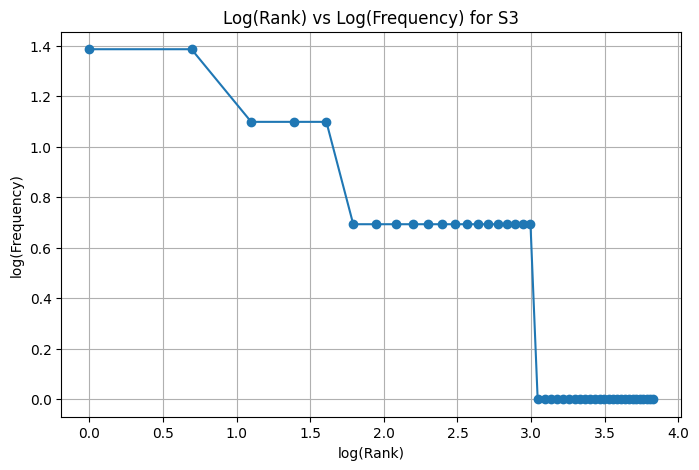


Top 5 Bigrams of S1:
[(('.', 'is'), 4), (('is', 'there'), 3), (('there', 'another'), 3), (('another', 'solution'), 3), (('solution', '?'), 3)]

Top 5 Bigrams of S3:
[(('another', 'solution'), 3), (('keeps', 'disconnecting'), 3), (('showing', 'error'), 2), (('stopped', 'syncing'), 2), (('assignment', 'deadline'), 2)]

TTR Comparison:
S1 TTR: 0.4938
S4 TTR: 0.6027


In [ ]:
# Your code
# Assignment 7 - Question 5
# Roll Number: 1024170122

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer

print("Q5: Corpus Statistics")
print("Fingerprint:", FINGERPRINT)

# Create token collections

S1 = []
S2 = []
S3 = []

for ticket in processed_tickets.values():

    tokens = ticket["tokens"]

    S1.extend(tokens)

    # Remove punctuation
    S2.extend([
        token for token in tokens
        if not is_punct(token)
    ])

    # Final tokens
    S3.extend(ticket["final"])


# S4: Porter stemming on final tokens
porter = PorterStemmer()

S4 = [porter.stem(token) for token in S3]


# Calculate corpus statistics
def corpus_stats(tokens):

    total = len(tokens)
    unique = len(set(tokens))

    ttr = unique / total if total > 0 else 0

    return {
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    }


# Create comparison table
stats = {
    "S1 - All Tokens": corpus_stats(S1),
    "S2 - No Punctuation": corpus_stats(S2),
    "S3 - Final Tokens": corpus_stats(S3),
    "S4 - Porter Stemmed": corpus_stats(S4)
}

stats_df = pd.DataFrame(stats).T

print("\nCorpus Statistics Table:")
display(stats_df)


# Top 10 words of S1
print("\nTop 10 Words in S1:")
print(Counter(S1).most_common(10))


# Top 10 words of S3
print("\nTop 10 Words in S3:")
print(Counter(S3).most_common(10))


# Plot log(rank) vs log(frequency) for S3

word_counts = Counter(S3)

frequencies = sorted(
    word_counts.values(),
    reverse=True
)

ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    np.log(ranks),
    np.log(frequencies),
    marker="o"
)

plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")

plt.grid(True)
plt.show()


# Top 5 bigrams of S1
print("\nTop 5 Bigrams of S1:")
print(Counter(bigrams(S1)).most_common(5))


# Top 5 bigrams of S3
print("\nTop 5 Bigrams of S3:")
print(Counter(bigrams(S3)).most_common(5))


# Observation
print("\nTTR Comparison:")

print("S1 TTR:", corpus_stats(S1)["TTR"])
print("S4 TTR:", corpus_stats(S4)["TTR"])

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

The Type-Token Ratio (TTR) changes from S1 to S4 because punctuation and stopwords are removed during preprocessing, and Porter stemming reduces different forms of words to common stems. These operations change the number of unique tokens relative to the total tokens, affecting lexical diversity.

## Q6. Interpretation

**(a) Why does TTR change from S1 to S4 in your dataset?**

The Type-Token Ratio increases from 0.4938 in S1 to 0.6027 in S4. This happens because punctuation and stopwords are removed, reducing the total number of tokens. Porter stemming also converts related word forms into common stems. In our dataset, S1 has 160 tokens and 79 unique tokens, while S4 has 73 tokens and 44 unique tokens.

**(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.**

In ticket T08, the word "doesn't" is preserved as a single token by our custom tokenizer. However, NLTK's word_tokenize() splits it into "does" and "n't". Our tokenizer preserves contractions, while word_tokenize() separates them.

**(c) Give one example where stemming produces an undesirable result.**

LancasterStemmer converts "urgent" into "urg". This is an example of over-stemming because it removes too many characters and produces an incomplete word.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**

For the word "another", PorterStemmer produces "anoth", whereas WordNetLemmatizer preserves "another". Lemmatization retains the meaningful word instead of reducing it to an incomplete stem.